# Entrega 3 · Modelado — Pronóstico dinámico de réplicas (B sin filtro, `root + gk3`)

Ciencia de Datos · UTN FRM · 2026

**Pregunta:** parados a $t$ horas de un sismo ($t \in \{1, 6, 24, 72, 168\}$), con lo que ya se observó hasta ese momento, ¿va a haber más réplicas antes de los 30 días? ¿Cuántas?

### Qué cambió respecto de `Entrega_3` y `Entrega_3_opcion1`
- **Dataset:** el mismo de `Entrega_3` (`mainshock=root`, `r_max=gk3`). `Entrega_3_opcion1` usaba `mainshock=largest` sin tope de distancia: el sismo principal era el mayor de la secuencia (algo que sólo se sabe cuando la secuencia terminó) y un sismo grande podía reclamar réplicas a más de 3.000 km.
- **Filas:** todas las de la tabla de horizontes, no sólo las que ya tenían réplicas (`n_aft_t > 0`). El modelo contesta para cualquier sismo; los sismos activos se reportan aparte, como subgrupo.
- **Validación:** por fecha y por sismo, con una purga de 30 días entre entrenamiento y validación.
- **Métrica principal:** PR-AUC de "¿habrá más réplicas?". El umbral de alerta se elige por costo, con validación cruzada.

La sección 12 muestra con un ejemplo qué recibe y qué devuelve el modelo. La sección 15 resume lo que se probó en `Entrega_3` y `Entrega_3_opcion1` y qué decidimos.

# 1. Configuración y datos

Los dos csv salen del DAG `detector_replicas_regions`. No se versionan: se generan con

```bash
cd pipeline
astro dev start
astro dev run dags trigger detector_replicas_regions --conf '{"mainshock": "root", "r_max_mode": "gk", "r_max_k": 3}'
```

y quedan en `pipeline/include/output/detector_replicas_api/delivery/`. Una sola semilla (`SEMILLA = 42`) para todo lo que la acepte.

In [1]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)
pd.set_option("display.float_format", "{:,.3f}".format)

SEMILLA = 42
np.random.seed(SEMILLA)

NOMBRE_CLUSTERS = "clusters_combined_5regions-c4d8c04f_rmax=gk3_mainshock=root_seed=1.csv"
NOMBRE_HORIZONS = "horizons_combined_5regions-c4d8c04f_rmax=gk3_mainshock=root_seed=1.csv"
DELIVERY = Path("pipeline") / "include" / "output" / "detector_replicas_api" / "delivery"


def resolver_archivo(nombre):
    """Busca el csv en el repo (corriendo desde la raíz o desde notebooks/); en Colab lo pide."""
    for ruta in [Path(nombre), DELIVERY / nombre, Path("..") / DELIVERY / nombre]:
        if ruta.exists():
            return ruta
    try:
        from google.colab import files  # type: ignore
        print(f"Subí '{nombre}':")
        files.upload()
        return Path(nombre)
    except ImportError:
        raise FileNotFoundError(f"No se encontró '{nombre}': hay que correr el DAG (ver arriba).")


clusters_raw = pd.read_csv(resolver_archivo(NOMBRE_CLUSTERS), low_memory=False)
horizons_raw = pd.read_csv(resolver_archivo(NOMBRE_HORIZONS), low_memory=False)
clusters_raw["mainshock_time"] = pd.to_datetime(clusters_raw["mainshock_time"], format="ISO8601", utc=True)

In [2]:
# Lo que se sabe del sismo en t = 0, pegado a cada fila (sismo, horizonte)
COLS_CLUSTER = ["cluster_id", "mainshock_place", "mainshock_time", "mainshock_mag", "mainshock_depth",
                "mainshock_lat", "mainshock_lon", "dist_to_border_km", "region_mc",
                "n_prior_2d", "n_prior_30d", "n_prior_365d", "prior_max_mag_365d", "days_since_prior"]

df_todo = horizons_raw.merge(clusters_raw[COLS_CLUSTER], on="cluster_id", how="left", validate="many_to_one")

# Afuera sólo las secuencias cuya ventana de 30 días se pasa del final del catálogo (censored_T):
# su objetivo está incompleto. NO se filtra por actividad (n_aft_t > 0).
df = (df_todo[~df_todo["censored_T"]]
      .sort_values(["mainshock_time", "cluster_id", "horizon_hours"])
      .reset_index(drop=True))

pd.Series({"secuencias en el csv": len(clusters_raw),
           "filas de horizontes (secuencias × 5)": len(horizons_raw),
           "secuencias censuradas a 30 días (afuera)": horizons_raw.loc[horizons_raw["censored_T"], "cluster_id"].nunique(),
           "filas que quedan": len(df),
           "secuencias que quedan": df["cluster_id"].nunique()})

secuencias en el csv                         21292
filas de horizontes (secuencias × 5)        106460
secuencias censuradas a 30 días (afuera)        68
filas que quedan                            106120
secuencias que quedan                        21224
dtype: int64

# 2. Qué predecimos

Cada fila es un par (sismo, horizonte $t$). Parados en $t$:
- **Lo que ya pasó:** el sismo principal (magnitud, profundidad, lugar, Mc de su región, sismicidad previa) y las réplicas entre $0$ y $t$: cuántas (`n_aft_t`), la mayor (`max_aft_mag_t`) y cuánto hace de la última (`hours_since_last_t`).
- **Lo que queremos saber:** `y_aft`, cuántas réplicas más hay entre $t$ y 30 días. La alerta es `y_aft > 0`.

In [3]:
activa = df["n_aft_t"] > 0
por_horizonte = pd.DataFrame({
    "filas": df.groupby("horizon_hours").size(),
    "% con réplicas hasta t (activas)": activa.groupby(df["horizon_hours"]).mean() * 100,
    "% con más réplicas · todas": df.groupby("horizon_hours")["y_has_aft"].mean() * 100,
    "% con más réplicas · activas": df[activa].groupby("horizon_hours")["y_has_aft"].mean() * 100,
    "% con más réplicas · tranquilas": df[~activa].groupby("horizon_hours")["y_has_aft"].mean() * 100,
    "media y_aft · activas": df[activa].groupby("horizon_hours")["y_aft"].mean(),
})
por_horizonte.loc["todas"] = [len(df), activa.mean() * 100, df["y_has_aft"].mean() * 100,
                              df.loc[activa, "y_has_aft"].mean() * 100, df.loc[~activa, "y_has_aft"].mean() * 100,
                              df.loc[activa, "y_aft"].mean()]
por_horizonte.round(2)

,filas,% con réplicas hasta t (activas),% con más réplicas · todas,% con más réplicas · activas,% con más réplicas · tranquilas,media y_aft · activas
horizon_hours,,,,,,
1,21224,4.100,8.360,45.350,6.780,7.800
6,21224,6.290,6.590,36.150,4.600,4.930
24,21224,7.900,4.840,27.030,2.940,3.310
72,21224,9.080,3.230,18.790,1.680,1.880
168,21224,9.770,2.000,11.910,0.920,0.980
todas,106120,7.430,5.000,24.610,3.430,3.120


El 5,0 % de las filas tiene más réplicas después de $t$. En las activas (7,4 % de las filas) es el 24,6 %; en las tranquilas, el 3,4 %.

Pero las tranquilas son tantas que **el 63,5 % de los casos con más réplicas viene de sismos que a la hora $t$ todavía no habían tenido ninguna** (a 1 h, el 77,7 %). Suelen ser pocas: mediana 1, sólo el 1 % llega a 11 o más, y suman el 21 % de todas las réplicas. Un modelo que sólo mire los sismos activos no puede avisar en esos casos.

## Las columnas que no pueden estar

- **Fuga:** `y_aft` y `y_has_aft` son la respuesta; `n_aft_T = n_aft_t + y_aft` la contiene.
- **Identificadores:** sirven para partir y auditar, no para predecir.
- **Candidatas:** sólo lo observable en el instante $t$.

In [4]:
FUGA = ["y_aft", "y_has_aft", "n_aft_T"]
IDS = ["cluster_id", "mainshock_place", "mainshock_time", "censored_T", "censored_t"]
CANDIDATAS = [
    # observadas entre 0 y t
    "horizon_hours", "n_aft_t", "max_aft_mag_t", "hours_since_last_t",
    # conocidas en t = 0
    "mainshock_mag", "mainshock_depth", "mainshock_lat", "mainshock_lon", "dist_to_border_km", "region", "region_mc",
    # sismicidad previa al sismo
    "n_prior_2d", "n_prior_30d", "n_prior_365d", "prior_max_mag_365d", "days_since_prior",
]
assert set(CANDIDATAS).isdisjoint(FUGA + IDS), "hay columnas de fuga o identificadores entre las candidatas"

# Con root, el "principal" es el primer sismo de la secuencia: puede venir una réplica mayor.
# Con largest esto sería 0 % por construcción, porque el principal se elige mirando el futuro.
mayor_que_principal = df.loc[activa, "max_aft_mag_t"] > df.loc[activa, "mainshock_mag"]
print(f"Filas activas donde ya llegó una réplica mayor que el principal: "
      f"{mayor_que_principal.sum():,} de {activa.sum():,} ({mayor_que_principal.mean() * 100:.1f} %)")

Filas activas donde ya llegó una réplica mayor que el principal: 2,460 de 7,884 (31.2 %)


En el 31,2 % de las filas activas ya llegó una réplica mayor que el sismo principal: el primero de la secuencia era un premonitor. Es lo que va a pasar en la app, que no sabe si el sismo que acaba de ocurrir va a ser el mayor. Con `mainshock=largest` estas filas no existirían y el problema parecería más fácil de lo que es.

# 3. Cómo partimos los datos

Las filas tienen **dos dependencias**:
1. **Están en el tiempo** y el modelo se va a usar con sismos futuros: se entrena con lo anterior y se valida con lo posterior.
2. **Se repiten por sismo** (hasta 5 horizontes): todas las filas de un sismo caen siempre del mismo lado.

Además hay una **purga de 30 días**: el objetivo de un sismo ocurrido 10 días antes del corte se termina de conocer 20 días *después* del corte. Si entrara al entrenamiento, el modelo aprendería de réplicas que, en el momento de predecir, todavía no habían ocurrido. Los sismos de los 30 días previos a cada corte no entran.

**Test:** el 20 % de los sismos más recientes. Se mira una sola vez, al final.

In [5]:
VENTANA = pd.Timedelta(days=30)

inicio = df.groupby("cluster_id")["mainshock_time"].min().sort_values()
corte = inicio.iloc[int(len(inicio) * 0.8)]
ids_train = set(inicio.index[inicio < corte - VENTANA])
ids_test = set(inicio.index[inicio >= corte])
assert ids_train.isdisjoint(ids_test)

train = df[df["cluster_id"].isin(ids_train)].reset_index(drop=True)
test = df[df["cluster_id"].isin(ids_test)].reset_index(drop=True)
X_train, y_train = train[CANDIDATAS], train["y_aft"].astype(float)
X_test, y_test = test[CANDIDATAS], test["y_aft"].astype(float)


def resumen_particion(d):
    act = d["n_aft_t"] > 0
    return {"filas": len(d), "sismos": d["cluster_id"].nunique(),
            "desde": d["mainshock_time"].min().date(), "hasta": d["mainshock_time"].max().date(),
            "% activas": act.mean() * 100, "% con más réplicas": d["y_has_aft"].mean() * 100,
            "% con más réplicas · activas": d.loc[act, "y_has_aft"].mean() * 100}


print(f"Purgados (sismos de los 30 días previos al corte): {len(inicio) - len(ids_train) - len(ids_test)}")
pd.DataFrame({"entrenamiento": resumen_particion(train), "test": resumen_particion(test)}).T

Purgados (sismos de los 30 días previos al corte): 77


,filas,sismos,desde,hasta,% activas,% con más réplicas,% con más réplicas · activas
entrenamiento,84510,16902,2003-01-01,2021-04-01,7.438,5.091,24.308
test,21225,4245,2021-05-02,2025-12-01,7.435,4.702,25.729


**Validación cruzada:** `TimeSeriesSplit` sobre los sismos ordenados por fecha (no sobre las filas), con la misma purga de 30 días antes de cada pedazo de validación. Es el mismo criterio que la partición de test.

In [6]:
from sklearn.model_selection import TimeSeriesSplit


def folds_temporales(datos, n_splits=5):
    """Pedazos por fecha y por sismo: se entrena con sismos anteriores y se valida con posteriores.

    Las filas de un mismo sismo caen siempre del mismo lado, y del entrenamiento se purgan
    los sismos de los 30 días previos a la validación, cuyo objetivo todavía no se conocía.
    """
    t = datos.groupby("cluster_id")["mainshock_time"].min().sort_values()
    folds = []
    for e, v in TimeSeriesSplit(n_splits=n_splits).split(t):
        inicio_val = t.iloc[v[0]]
        ids_e = t.index[e][(t.iloc[e] < inicio_val - VENTANA).to_numpy()]
        ids_v = t.index[v]
        folds.append((np.flatnonzero(datos["cluster_id"].isin(ids_e)),
                      np.flatnonzero(datos["cluster_id"].isin(ids_v))))
    return folds


cv = folds_temporales(train)
pd.DataFrame([{"entrena hasta": train["mainshock_time"].iloc[e].max().date(),
               "valida desde": train["mainshock_time"].iloc[v].min().date(),
               "valida hasta": train["mainshock_time"].iloc[v].max().date(),
               "sismos entrenamiento": train["cluster_id"].iloc[e].nunique(),
               "sismos validación": train["cluster_id"].iloc[v].nunique(),
               "% con más réplicas (val)": train["y_has_aft"].iloc[v].mean() * 100,
               "sismos compartidos": len(set(train["cluster_id"].iloc[e]) & set(train["cluster_id"].iloc[v]))}
              for e, v in cv], index=[f"fold {i + 1}" for i in range(len(cv))])

,entrena hasta,valida desde,valida hasta,sismos entrenamiento,sismos validación,% con más réplicas (val),sismos compartidos
fold 1,2006-10-03,2006-11-02,2010-03-28,2752,2817,5.644,0
fold 2,2010-02-26,2010-03-28,2012-09-21,5533,2817,4.615,0
fold 3,2012-08-22,2012-09-21,2015-05-03,8363,2817,4.175,0
fold 4,2015-04-03,2015-05-03,2018-04-19,11208,2817,5.346,0
fold 5,2018-03-20,2018-04-19,2021-04-01,14008,2817,4.757,0


# 4. La métrica

**Métrica principal: PR-AUC de "¿habrá más réplicas después de $t$?" (`y_aft > 0`), sobre todas las filas.**

- La decisión que toma la app es **avisar o no avisar**. Sólo el 5 % de las filas tiene más réplicas: la accuracy premiaría decir siempre "no".
- El **MAE en escala log** tampoco sirve como métrica principal sobre todas las filas: con 95 % de ceros, el piso que dice siempre 0 es casi imbatible (es el error de la accuracy con otro nombre). Lo usamos para el **cuántas**, sobre los sismos activos.
- **PR-AUC** mide qué tan bien ordena el modelo: si los sismos que van a tener réplicas quedan arriba en la lista. No depende de un umbral (ése se elige después, por costo) y su piso es conocido: un modelo al azar saca la proporción de positivos.

**Secundarias:** PR-AUC sobre los activos; `MAE_log` y MAE en réplicas sobre los activos; precisión, recall y F1 con el umbral elegido.

In [7]:
from sklearn.metrics import average_precision_score, f1_score, mean_absolute_error, precision_score, recall_score


def pr_auc(y, pred):
    return average_precision_score(np.asarray(y) > 0, pred)


def mae_log(y, pred):
    return mean_absolute_error(np.log1p(y), np.log1p(np.clip(pred, 0, None)))


def _pred(est, X):
    return np.clip(est.predict(X), 0, None)


def _activas(X):
    return (X["n_aft_t"] > 0).to_numpy()


# Scorers con la firma (estimador, X, y): necesitan X para quedarse con las filas activas.
def score_pr_auc(est, X, y):
    return pr_auc(y, _pred(est, X))


def score_pr_auc_act(est, X, y):
    m = _activas(X)
    return pr_auc(np.asarray(y)[m], _pred(est, X[m]))


def score_mae_log_act(est, X, y):
    m = _activas(X)
    return -mae_log(np.asarray(y)[m], _pred(est, X[m]))


def score_mae_rep_act(est, X, y):
    m = _activas(X)
    return -mean_absolute_error(np.asarray(y)[m], _pred(est, X[m]))


SCORERS = {"pr_auc": score_pr_auc, "pr_auc_act": score_pr_auc_act,
           "mae_log_act": score_mae_log_act, "mae_rep_act": score_mae_rep_act}

## Todo adentro de un pipeline

`ColumnasHorizontes` arma las columnas con lo aprendido **sólo del entrenamiento de cada pedazo** (las regiones y las medianas para imputar), con interruptores por bloque para medir qué aporta cada uno:
- **Principal:** `mainshock_mag` (o `mag_sobre_mc = mainshock_mag - region_mc`), profundidad y `log(1 + horizonte)`.
- **Observado hasta $t$:** `log(1 + n_aft_t)`, si hubo actividad, la mayor réplica y `log(1 + horas desde la última)`.
- **Derivadas hasta $t$:** tasa por hora, déficit de Båth (`mainshock_mag − mayor réplica`) y fracción del tiempo en silencio.
- **Posición y región:** latitud, longitud, distancia al borde y una columna 0/1 por región.
- **Sismicidad previa:** sismos en los 2, 30 y 365 días previos, la mayor del último año y días desde el último.

**Sin réplicas hasta $t$**, la mayor réplica no existe. El pipeline descarta todo lo que está por debajo de Mc antes de armar las secuencias, así que la mayor posible quedó por debajo de Mc: usamos `region_mc` como cota en vez de rellenar con una mediana.

El regresor aprende `log(1 + y_aft)` (unos pocos megasismos tienen miles de réplicas y dominarían el error) y devuelve réplicas.

In [8]:
from sklearn.base import BaseEstimator, RegressorMixin, TransformerMixin, clone
from sklearn.compose import TransformedTargetRegressor
from sklearn.impute import SimpleImputer
from sklearn.model_selection import cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler


class ColumnasHorizontes(BaseEstimator, TransformerMixin):
    """Arma las columnas dentro del pipeline, con un interruptor por bloque."""

    def __init__(self, usar_mag_sobre_mc=True, con_observado_t=True, con_derivadas_t=True,
                 con_posicion_region=True, con_previos=False):
        self.usar_mag_sobre_mc = usar_mag_sobre_mc
        self.con_observado_t = con_observado_t
        self.con_derivadas_t = con_derivadas_t
        self.con_posicion_region = con_posicion_region
        self.con_previos = con_previos

    def fit(self, X, y=None):
        # se aprende sólo del entrenamiento
        self.regiones_ = sorted(X["region"].dropna().unique())
        self.mediana_prior_mag_ = float(X["prior_max_mag_365d"].median())
        self.mediana_days_prior_ = float(X["days_since_prior"].median())
        return self

    def transform(self, X):
        out = pd.DataFrame(index=X.index)
        if self.usar_mag_sobre_mc:
            out["mag_sobre_mc"] = X["mainshock_mag"] - X["region_mc"]
        else:
            out["mainshock_mag"] = X["mainshock_mag"]
        out["mainshock_depth"] = X["mainshock_depth"]
        out["log_horizon_hours"] = np.log1p(X["horizon_hours"])

        # sin réplicas hasta t, la mayor quedó por debajo de Mc
        mayor_t = X["max_aft_mag_t"].fillna(X["region_mc"])
        if self.con_observado_t:
            out["log_n_aft_t"] = np.log1p(X["n_aft_t"])
            out["hubo_actividad"] = (X["n_aft_t"] > 0).astype(float)
            out["max_aft_mag_t"] = mayor_t
            out["log_hours_since_last_t"] = np.log1p(X["hours_since_last_t"])
        if self.con_derivadas_t:
            out["tasa_por_hora_log"] = np.log1p(X["n_aft_t"] / X["horizon_hours"])
            out["deficit_bath"] = X["mainshock_mag"] - mayor_t
            out["ratio_silencio"] = X["hours_since_last_t"] / X["horizon_hours"]
        if self.con_posicion_region:
            out["mainshock_lat"] = X["mainshock_lat"]
            out["mainshock_lon"] = X["mainshock_lon"]
            out["dist_to_border_km"] = X["dist_to_border_km"]
            for r in self.regiones_[1:]:
                out[f"region_{r}"] = (X["region"] == r).astype(float)
        if self.con_previos:
            out["log_n_prior_2d"] = np.log1p(X["n_prior_2d"])
            out["log_n_prior_30d"] = np.log1p(X["n_prior_30d"])
            out["log_n_prior_365d"] = np.log1p(X["n_prior_365d"])
            out["prior_max_mag_365d"] = X["prior_max_mag_365d"].fillna(self.mediana_prior_mag_)
            out["log_days_since_prior"] = np.log1p(X["days_since_prior"].fillna(self.mediana_days_prior_))
        return out


def expm1_no_negativo(y_log):
    return np.expm1(np.clip(y_log, 0.0, 15.0))


def armar_pipeline(regresor, **bloques):
    """Columnas, imputación, escala y el regresor sobre log(1 + y)."""
    return Pipeline([
        ("columnas", ColumnasHorizontes(**bloques)),
        ("imputar", SimpleImputer(strategy="median")),
        ("escalar", StandardScaler()),
        ("modelo", TransformedTargetRegressor(regressor=regresor, func=np.log1p,
                                              inverse_func=expm1_no_negativo, check_inverse=False)),
    ])


resultados = {}
por_fold = {}


def validar(nombre, pipeline, folds=None):
    r = cross_validate(pipeline, X_train, y_train, cv=folds or cv, scoring=SCORERS, n_jobs=-1)
    por_fold[nombre] = r
    resultados[nombre] = {"PR-AUC": r["test_pr_auc"].mean(), "± PR-AUC": r["test_pr_auc"].std(),
                          "PR-AUC activas": r["test_pr_auc_act"].mean(),
                          "MAE_log activas": -r["test_mae_log_act"].mean(), "± MAE_log": r["test_mae_log_act"].std(),
                          "MAE réplicas activas": -r["test_mae_rep_act"].mean()}
    return pd.DataFrame(resultados).T.round(3)


def diferencia_pareada(a, b, clave="pr_auc"):
    """a − b fold a fold (positivo: gana a en PR-AUC; en MAE, por el signo del scorer, también)."""
    d = por_fold[a][f"test_{clave}"] - por_fold[b][f"test_{clave}"]
    return f"{a} − {b} [{clave}]: {d.mean():+.4f} ± {d.std():.4f} (gana {a} en {(d > 0).sum()}/{len(d)} pedazos)"

# 5. El piso

- **Siempre 0** (`DummyRegressor`): no mira ninguna columna. Su PR-AUC es la proporción de positivos.
- **Regla de sentido común:** "van a venir tantas como las que ya vinieron" (`ŷ = n_aft_t`). No aprende nada, pero sí mira lo observado. Si el modelo no le gana a esto, no vale la pena.

In [9]:
from sklearn.dummy import DummyRegressor


class ReglaObservado(BaseEstimator, RegressorMixin):
    """Sin aprender nada: tantas réplicas más como las que ya hubo."""

    def fit(self, X, y):
        return self

    def predict(self, X):
        return X["n_aft_t"].to_numpy(dtype=float)


validar("piso: siempre 0", armar_pipeline(DummyRegressor(strategy="constant", constant=0.0)))
validar("regla: ŷ = n_aft_t", ReglaObservado())

,PR-AUC,± PR-AUC,PR-AUC activas,MAE_log activas,± MAE_log,MAE réplicas activas
piso: siempre 0,0.049,0.005,0.242,0.339,0.011,3.382
regla: ŷ = n_aft_t,0.195,0.005,0.463,0.791,0.025,4.097


- El piso saca **PR-AUC 0,049**, la proporción de positivos, y **MAE_log 0,339** en las activas.
- La regla "van a venir tantas como las que vinieron" ordena mejor que el azar (0,195), pero erra mucho la cantidad (MAE_log 0,791): sirve como piso para ordenar, no para contar.

# 6. ¿Qué columnas aportan?

Agregamos los bloques de a uno, con el modelo lineal simple (`Ridge`) y con `HistGradientBoosting`, sobre los mismos pedazos. El bloque A es **lo que se sabe en $t = 0$** (más el horizonte): la diferencia entre A y C es lo que se gana por esperar $t$ horas y mirar.

In [10]:
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.linear_model import Ridge

BLOQUES = {
    "A. sólo el principal (lo que se sabe en t = 0)": dict(usar_mag_sobre_mc=False, con_observado_t=False, con_derivadas_t=False, con_posicion_region=False),
    "B. + mag_sobre_mc": dict(usar_mag_sobre_mc=True, con_observado_t=False, con_derivadas_t=False, con_posicion_region=False),
    "C. + observado hasta t": dict(con_observado_t=True, con_derivadas_t=False, con_posicion_region=False),
    "D. + derivadas (tasa, Båth, silencio)": dict(con_derivadas_t=True, con_posicion_region=False),
    "E. + posición y región": dict(con_posicion_region=True),
    "F. + sismicidad previa": dict(con_posicion_region=True, con_previos=True),
}


def hgb(**params):
    base = dict(learning_rate=0.05, max_depth=7, min_samples_leaf=30)
    return HistGradientBoostingRegressor(random_state=SEMILLA, **{**base, **params})


filas = {}
for nombre, bloques in BLOQUES.items():
    fila = {}
    for familia, regresor in [("Ridge", Ridge(alpha=10.0)), ("HGB", hgb())]:
        r = cross_validate(armar_pipeline(regresor, **bloques), X_train, y_train, cv=cv, scoring=SCORERS, n_jobs=-1)
        fila[f"{familia} PR-AUC"] = f"{r['test_pr_auc'].mean():.3f} ± {r['test_pr_auc'].std():.3f}"
        fila[f"{familia} PR-AUC activas"] = f"{r['test_pr_auc_act'].mean():.3f}"
        fila[f"{familia} MAE_log activas"] = f"{-r['test_mae_log_act'].mean():.3f} ± {r['test_mae_log_act'].std():.3f}"
    filas[nombre] = fila
tabla_bloques = pd.DataFrame(filas).T
tabla_bloques

,Ridge PR-AUC,Ridge PR-AUC activas,Ridge MAE_log activas,HGB PR-AUC,HGB PR-AUC activas,HGB MAE_log activas
A. sólo el principal (lo que se sabe en t = 0),0.322 ± 0.018,0.608,0.354 ± 0.012,0.311 ± 0.018,0.633,0.294 ± 0.025
B. + mag_sobre_mc,0.338 ± 0.014,0.610,0.353 ± 0.012,0.327 ± 0.016,0.634,0.294 ± 0.020
C. + observado hasta t,0.344 ± 0.014,0.590,0.361 ± 0.006,0.395 ± 0.023,0.687,0.298 ± 0.009
"D. + derivadas (tasa, Båth, silencio)",0.367 ± 0.020,0.647,0.321 ± 0.007,0.395 ± 0.025,0.685,0.295 ± 0.008
E. + posición y región,0.369 ± 0.020,0.648,0.319 ± 0.006,0.396 ± 0.021,0.692,0.292 ± 0.009
F. + sismicidad previa,0.370 ± 0.020,0.649,0.319 ± 0.007,0.401 ± 0.030,0.693,0.293 ± 0.009


- **A → C, lo observado hasta $t$, es el salto grande.** En HGB, el PR-AUC pasa de 0,327 a 0,395 (+0,068, unas tres veces el desvío), y en las activas de 0,634 a 0,687. Es lo que se gana por esperar $t$ horas y mirar: la comparación justa entre el enfoque estático (`Entrega_3`) y el dinámico, sobre las mismas filas.
- **A → B (`mag_sobre_mc`):** +0,016 en las dos familias, en el límite del desvío. Lo dejamos por la razón física: cada región detecta a partir de un Mc distinto.
- **C → D (derivadas):** para HGB no cambia nada (0,395 → 0,395), pero para Ridge sí: 0,344 → 0,367, y el MAE_log de las activas baja de 0,361 a 0,321. El modelo lineal no arma solo la tasa ni el déficit de Båth; el árbol sí.
- **E (posición y región) y F (sismicidad previa)** no le ganan a D por más que el desvío en ninguna de las dos familias (HGB 0,396 y 0,401 ± 0,030). Quedan afuera.

**Elegimos D:** el bloque más chico después del cual nada mejora por más que el ruido.

In [11]:
BLOQUE_ELEGIDO = "D. + derivadas (tasa, Båth, silencio)"
COLUMNAS_ELEGIDAS = BLOQUES[BLOQUE_ELEGIDO]
print("Bloque elegido:", BLOQUE_ELEGIDO, COLUMNAS_ELEGIDAS)

Bloque elegido: D. + derivadas (tasa, Båth, silencio) {'con_derivadas_t': True, 'con_posicion_region': False}


# 7. ¿Filtrar o no filtrar?

`Entrega_3_opcion1` entrenaba sólo con las filas que ya tenían réplicas hasta $t$. Lo comparamos sobre los mismos pedazos y medido dos veces:
- **en las filas activas** (la pregunta de la opción 1): mismo examen, distinto entrenamiento;
- **en todas las filas** (la pregunta completa): el modelo filtrado no sabe qué hacer con un sismo tranquilo, así que contesta 0 (no avisa).

In [12]:
filas = []
for k, (e, v) in enumerate(cv):
    Xe, ye, Xv, yv = X_train.iloc[e], y_train.iloc[e], X_train.iloc[v], y_train.iloc[v]
    act_e, act_v = _activas(Xe), _activas(Xv)
    sin_filtro = armar_pipeline(hgb(), **COLUMNAS_ELEGIDAS).fit(Xe, ye)
    filtrado = armar_pipeline(hgb(), **COLUMNAS_ELEGIDAS).fit(Xe[act_e], ye[act_e])
    p_sin = _pred(sin_filtro, Xv)
    p_fil = np.zeros(len(Xv))
    p_fil[act_v] = _pred(filtrado, Xv[act_v])
    for nombre, p, n_train in [("sin filtro", p_sin, len(Xe)), ("filtrado (n_aft_t > 0)", p_fil, int(act_e.sum()))]:
        filas.append({"pedazo": k + 1, "modelo": nombre, "filas de entrenamiento": n_train,
                      "PR-AUC · todas": pr_auc(yv, p), "PR-AUC · activas": pr_auc(yv[act_v], p[act_v]),
                      "MAE_log · activas": mae_log(yv[act_v], p[act_v])})
filtro = pd.DataFrame(filas)
resumen_filtro = filtro.groupby("modelo")[["filas de entrenamiento", "PR-AUC · todas", "PR-AUC · activas", "MAE_log · activas"]].agg(["mean", "std"])
pareada = filtro.pivot(index="pedazo", columns="modelo")
dif = {m: (pareada[(m, "sin filtro")] - pareada[(m, "filtrado (n_aft_t > 0)")]) for m in ["PR-AUC · todas", "PR-AUC · activas", "MAE_log · activas"]}
display(resumen_filtro.round(3))
pd.DataFrame({m: {"sin filtro − filtrado (media)": d.mean(), "desvío": d.std()} for m, d in dif.items()}).T.round(4)

filas de entrenamiento            PR-AUC · todas       PR-AUC · activas       MAE_log · activas      
                                         mean        std           mean   std             mean   std              mean   std
modelo                                                                                                                      
filtrado (n_aft_t > 0)              3,287.600  1,633.548          0.273 0.023            0.684 0.031             0.298 0.009
sin filtro                         41,864.000 22,283.934          0.395 0.028            0.685 0.032             0.295 0.009

,sin filtro − filtrado (media),desvío
PR-AUC · todas,0.122,0.008
PR-AUC · activas,0.000,0.009
MAE_log · activas,-0.003,0.003


- **Mismo examen (activas): empate.** PR-AUC 0,684 contra 0,685 (diferencia 0,000 ± 0,009) y MAE_log 0,298 contra 0,295 (−0,003 ± 0,003). Entrenar con 12 veces menos filas no mejora ni empeora al modelo en su propia pregunta.
- **Pregunta completa (todas): gana sin filtro**, 0,395 contra 0,273 (+0,122 ± 0,008), porque el modelo filtrado no puede avisar en el 63 % de los casos, los que vienen de sismos tranquilos.

Achicar el dataset no compra mejores métricas: sólo cambia la pregunta y saca cobertura. Por eso entrenamos con todas las filas.

# 8. Comparación de familias

Con las columnas elegidas y los mismos pedazos: el modelo lineal simple primero, y después un árbol, un bosque y un boosting.

In [13]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.tree import DecisionTreeRegressor

validar("lineal simple (Ridge)", armar_pipeline(Ridge(alpha=10.0), **COLUMNAS_ELEGIDAS))
validar("árbol de decisión", armar_pipeline(DecisionTreeRegressor(max_depth=5, min_samples_leaf=30, random_state=SEMILLA), **COLUMNAS_ELEGIDAS))
validar("random forest", armar_pipeline(RandomForestRegressor(n_estimators=200, max_depth=10, min_samples_leaf=15,
                                                              n_jobs=2, random_state=SEMILLA), **COLUMNAS_ELEGIDAS))
validar("HistGradientBoosting", armar_pipeline(hgb(), **COLUMNAS_ELEGIDAS))

,PR-AUC,± PR-AUC,PR-AUC activas,MAE_log activas,± MAE_log,MAE réplicas activas
piso: siempre 0,0.049,0.005,0.242,0.339,0.011,3.382
regla: ŷ = n_aft_t,0.195,0.005,0.463,0.791,0.025,4.097
lineal simple (Ridge),0.367,0.020,0.647,0.321,0.007,2.564
árbol de decisión,0.309,0.021,0.613,0.308,0.011,3.213
random forest,0.394,0.019,0.692,0.299,0.011,2.925
HistGradientBoosting,0.395,0.025,0.685,0.295,0.008,2.968


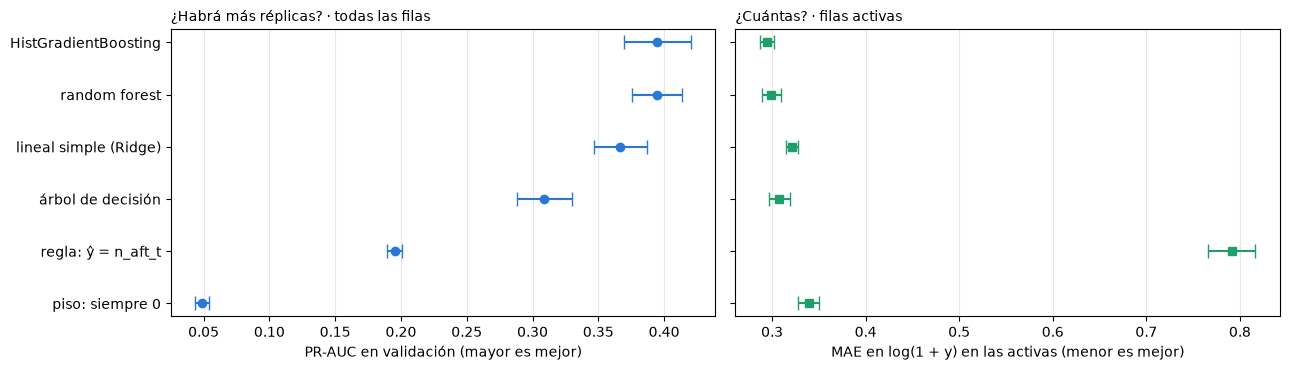

HistGradientBoosting − lineal simple (Ridge) [pr_auc]: +0.0281 ± 0.0082 (gana HistGradientBoosting en 5/5 pedazos)
HistGradientBoosting − lineal simple (Ridge) [mae_log_act]: +0.0265 ± 0.0051 (gana HistGradientBoosting en 5/5 pedazos)
HistGradientBoosting − random forest [pr_auc]: +0.0004 ± 0.0072 (gana HistGradientBoosting en 1/5 pedazos)
HistGradientBoosting − random forest [mae_log_act]: +0.0044 ± 0.0044 (gana HistGradientBoosting en 4/5 pedazos)
lineal simple (Ridge) − regla: ŷ = n_aft_t [pr_auc]: +0.1715 ± 0.0164 (gana lineal simple (Ridge) en 5/5 pedazos)
lineal simple (Ridge) − regla: ŷ = n_aft_t [mae_log_act]: +0.4701 ± 0.0228 (gana lineal simple (Ridge) en 5/5 pedazos)


In [14]:
tabla = pd.DataFrame(resultados).T.sort_values("PR-AUC")
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8), sharey=True)
axes[0].errorbar(tabla["PR-AUC"], tabla.index, xerr=tabla["± PR-AUC"], fmt="o", color="#2a78d6", capsize=5)
axes[0].set_xlabel("PR-AUC en validación (mayor es mejor)")
axes[0].set_title("¿Habrá más réplicas? · todas las filas", fontsize=10, loc="left")
axes[1].errorbar(tabla["MAE_log activas"], tabla.index, xerr=tabla["± MAE_log"], fmt="s", color="#1f9e6b", capsize=5)
axes[1].set_xlabel("MAE en log(1 + y) en las activas (menor es mejor)")
axes[1].set_title("¿Cuántas? · filas activas", fontsize=10, loc="left")
for ax in axes:
    ax.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

for a, b in [("HistGradientBoosting", "lineal simple (Ridge)"), ("HistGradientBoosting", "random forest"),
             ("lineal simple (Ridge)", "regla: ŷ = n_aft_t")]:
    print(diferencia_pareada(a, b, "pr_auc"))
    print(diferencia_pareada(a, b, "mae_log_act"))

- Todas las familias le ganan al piso y a la regla.
- **HGB contra el lineal simple:** +0,028 ± 0,008 de PR-AUC y mejor MAE_log en las activas (0,295 contra 0,321), ganando en los 5 pedazos. La diferencia es mayor que el desvío, así que se justifica el modelo más complejo.
- **HGB contra random forest:** empate (0,395 contra 0,394; +0,0004 ± 0,007). Elegimos HGB: mismo resultado, entrena más rápido y acepta faltantes.
- **Lo que no gana:** en MAE en réplicas (sin log) sobre las activas, Ridge erra menos (2,56 contra 2,97). HGB acierta mejor el orden de magnitud, pero se equivoca más en las pocas secuencias enormes, donde una diferencia en réplicas pesa mucho.
- El árbol solo (0,309) queda abajo de todos.

## ¿Qué le pasa al número si los pedazos se arman al azar?

In [15]:
from sklearn.model_selection import GroupKFold, KFold

control = {}
for nombre, folds in [("por fecha y por sismo (el nuestro)", cv),
                      ("por sismo, sin fecha (GroupKFold)", list(GroupKFold(n_splits=5).split(X_train, groups=train["cluster_id"]))),
                      ("al azar (KFold)", list(KFold(n_splits=5, shuffle=True, random_state=SEMILLA).split(X_train)))]:
    r = cross_validate(armar_pipeline(hgb(), **COLUMNAS_ELEGIDAS), X_train, y_train, cv=folds, scoring=SCORERS, n_jobs=-1)
    control[nombre] = {"PR-AUC": r["test_pr_auc"].mean(), "PR-AUC activas": r["test_pr_auc_act"].mean(),
                       "MAE_log activas": -r["test_mae_log_act"].mean()}
pd.DataFrame(control).T.round(3)

,PR-AUC,PR-AUC activas,MAE_log activas
por fecha y por sismo (el nuestro),0.395,0.685,0.295
"por sismo, sin fecha (GroupKFold)",0.412,0.704,0.289
al azar (KFold),0.434,0.733,0.276


- **Al azar (`KFold`):** PR-AUC 0,434 en vez de 0,395 (+10 %), y MAE_log 0,276 en vez de 0,295. Esa diferencia es fuga: las 5 filas de un mismo sismo quedan de los dos lados.
- **Por sismo pero sin fecha (`GroupKFold`, lo que usaba la opción 1):** 0,412, todavía optimista, porque valida sismos del pasado entrenando con el futuro.

# 9. Ajuste de hiperparámetros del elegido

Grilla completa sobre `max_depth`, `min_samples_leaf` y `learning_rate`, con los mismos pedazos. **Regla de elección:** entre las combinaciones cuyo PR-AUC está a menos de un desvío de la mejor, la más simple (menos profundidad, hojas más grandes, paso más chico). Si la compleja no le gana a la simple por más que el ruido, se queda la simple.

In [16]:
from sklearn.model_selection import GridSearchCV

GRILLA = {"modelo__regressor__max_depth": [3, 5, 7],
          "modelo__regressor__min_samples_leaf": [15, 30, 60],
          "modelo__regressor__learning_rate": [0.05, 0.10]}


def mas_simple_dentro_de_un_desvio(cv_results):
    r = pd.DataFrame(cv_results)
    mejor = r["mean_test_pr_auc"].idxmax()
    candidatos = r[r["mean_test_pr_auc"] >= r.loc[mejor, "mean_test_pr_auc"] - r.loc[mejor, "std_test_pr_auc"]]
    candidatos = candidatos.sort_values(["param_modelo__regressor__max_depth", "param_modelo__regressor__min_samples_leaf",
                                         "param_modelo__regressor__learning_rate"], ascending=[True, False, True])
    return int(candidatos.index[0])


busqueda = GridSearchCV(armar_pipeline(HistGradientBoostingRegressor(random_state=SEMILLA), **COLUMNAS_ELEGIDAS),
                        GRILLA, cv=cv, scoring=SCORERS, refit=mas_simple_dentro_de_un_desvio,
                        n_jobs=-1, return_train_score=True)
busqueda.fit(X_train, y_train)

r = pd.DataFrame(busqueda.cv_results_)
tabla_grilla = pd.DataFrame({
    "max_depth": r["param_modelo__regressor__max_depth"],
    "min_samples_leaf": r["param_modelo__regressor__min_samples_leaf"],
    "learning_rate": r["param_modelo__regressor__learning_rate"],
    "PR-AUC val": r["mean_test_pr_auc"], "± val": r["std_test_pr_auc"],
    "PR-AUC train": r["mean_train_pr_auc"],
    "brecha": r["mean_train_pr_auc"] - r["mean_test_pr_auc"],
    "PR-AUC val activas": r["mean_test_pr_auc_act"],
    "MAE_log val activas": -r["mean_test_mae_log_act"],
    "elegida": ["◀" if i == busqueda.best_index_ else "" for i in r.index],
}).sort_values("PR-AUC val", ascending=False)
print("Elegida:", {k.split("__")[-1]: v for k, v in busqueda.best_params_.items()})
tabla_grilla.round(4)

Elegida: {'learning_rate': 0.05, 'max_depth': 3, 'min_samples_leaf': 60}


,max_depth,min_samples_leaf,learning_rate,PR-AUC val,± val,PR-AUC train,brecha,PR-AUC val activas,MAE_log val activas,elegida
0,3,15,0.050,0.400,0.025,0.452,0.052,0.697,0.294,
4,5,30,0.050,0.400,0.025,0.470,0.070,0.694,0.294,
3,5,15,0.050,0.399,0.027,0.486,0.087,0.694,0.294,
10,3,30,0.100,0.399,0.025,0.469,0.070,0.694,0.295,
13,5,30,0.100,0.399,0.026,0.482,0.083,0.692,0.296,
9,3,15,0.100,0.396,0.024,0.476,0.079,0.692,0.295,
1,3,30,0.050,0.396,0.025,0.448,0.052,0.693,0.297,
5,5,60,0.050,0.396,0.024,0.461,0.065,0.688,0.298,
11,3,60,0.100,0.396,0.024,0.461,0.066,0.687,0.297,
7,7,30,0.050,0.395,0.025,0.495,0.100,0.685,0.295,


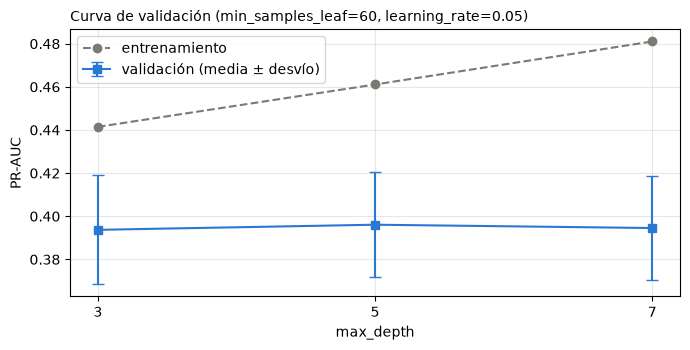

In [17]:
elegida = tabla_grilla[tabla_grilla["elegida"] == "◀"].iloc[0]
curva = tabla_grilla[(tabla_grilla["min_samples_leaf"] == elegida["min_samples_leaf"])
                     & (tabla_grilla["learning_rate"] == elegida["learning_rate"])].sort_values("max_depth")
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.plot(curva["max_depth"], curva["PR-AUC train"], "o--", color="#7a7974", label="entrenamiento")
ax.errorbar(curva["max_depth"], curva["PR-AUC val"], yerr=curva["± val"], fmt="s-", color="#2a78d6", capsize=4,
            label="validación (media ± desvío)")
ax.set_xlabel("max_depth")
ax.set_ylabel("PR-AUC")
ax.set_title(f"Curva de validación (min_samples_leaf={int(elegida['min_samples_leaf'])}, "
             f"learning_rate={elegida['learning_rate']})", fontsize=10, loc="left")
ax.set_xticks(curva["max_depth"])
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

- La grilla es plana: de 0,382 a 0,400 de PR-AUC, con desvíos de ~0,025. Las 18 combinaciones quedan a menos de un desvío de la mejor (0,400 ± 0,025), así que la regla elige la más simple: **`max_depth=3`, `min_samples_leaf=60`, `learning_rate=0,05`** (0,394 ± 0,025). Es además la de menor brecha con el entrenamiento (0,048).
- La curva muestra el sobreajuste del otro extremo: con `max_depth=7`, hojas de 15 y paso 0,10, el entrenamiento sube a 0,554 y la validación baja a 0,382.

# 10. El umbral de alerta, elegido por costo

El modelo devuelve cuántas réplicas espera ($\hat y$). Para avisar hay que elegir un umbral: **avisar si $\hat y \ge u$**. La regla de `Entrega_3_opcion1` era redondear ($u = 0{,}5$), que es arbitraria.

Lo elegimos minimizando el costo esperado, con predicciones **de validación** (cada fila predicha por un modelo que no la vio):

$$\text{costo}(u) = C_{\text{falsa alarma}} \cdot FP(u) + C_{\text{no avisar}} \cdot FN(u)$$

**Los costos son una decisión del grupo, no de los datos.** En `Entrega_3` dijimos que preferimos avisar de más antes que no detectar: un aviso que no se dio cuesta más que uno de más. Declaramos que **no avisar cuesta 3 veces más que una falsa alarma**, y mostramos cómo cambia el umbral con otras proporciones.

In [18]:
COSTO_FALSA_ALARMA = 1.0
COSTO_NO_AVISAR = 3.0

modelo_elegido = clone(busqueda.best_estimator_)
partes = []
for k, (e, v) in enumerate(cv):
    m = clone(modelo_elegido).fit(X_train.iloc[e], y_train.iloc[e])
    partes.append(pd.DataFrame({"pedazo": k + 1, "y": y_train.iloc[v].to_numpy(),
                                "pred": _pred(m, X_train.iloc[v]), "activa": _activas(X_train.iloc[v])}))
validacion = pd.concat(partes, ignore_index=True)

UMBRALES = np.geomspace(0.01, 20, 400)


def barrido(datos, c_fa=COSTO_FALSA_ALARMA, c_na=COSTO_NO_AVISAR):
    """Costo por fila, precisión y recall para cada umbral."""
    pos = datos["y"].to_numpy() > 0
    p = datos["pred"].to_numpy()
    alerta = p[None, :] >= UMBRALES[:, None]
    tp = (alerta & pos).sum(axis=1)
    fp = (alerta & ~pos).sum(axis=1)
    fn = (~alerta & pos).sum(axis=1)
    return pd.DataFrame({"umbral": UMBRALES, "costo": (c_fa * fp + c_na * fn) / len(p),
                         "precisión": tp / np.maximum(tp + fp, 1), "recall": tp / pos.sum(),
                         "% filas con alerta": alerta.mean(axis=1) * 100})


def umbral_optimo(c_fa, c_na):
    """El umbral que minimiza el costo medio entre pedazos, y el óptimo de cada pedazo por separado."""
    por_pedazo = [barrido(g, c_fa, c_na) for _, g in validacion.groupby("pedazo")]
    costo_medio = np.mean([b["costo"].to_numpy() for b in por_pedazo], axis=0)
    return UMBRALES[costo_medio.argmin()], [b.loc[b["costo"].idxmin(), "umbral"] for b in por_pedazo]


def con_umbral(datos, u):
    pos, alerta = datos["y"].to_numpy() > 0, datos["pred"].to_numpy() >= u
    return {"precisión": precision_score(pos, alerta, zero_division=0), "recall": recall_score(pos, alerta),
            "F1": f1_score(pos, alerta), "% filas con alerta": alerta.mean() * 100,
            "falsas alarmas por acierto": (alerta & ~pos).sum() / max((alerta & pos).sum(), 1)}


filas = {}
for proporcion in [1, 2, 3, 5, 10]:
    u, por_pedazo = umbral_optimo(1.0, float(proporcion))
    filas[f"no avisar = {proporcion} × falsa alarma"] = {"umbral (ŷ ≥)": u, "rango entre pedazos": f"{min(por_pedazo):.2f} – {max(por_pedazo):.2f}",
                                                          **con_umbral(validacion, u)}
filas["regla anterior: redondear (ŷ ≥ 0,5)"] = {"umbral (ŷ ≥)": 0.5, "rango entre pedazos": "–", **con_umbral(validacion, 0.5)}
tabla_umbrales = pd.DataFrame(filas).T
UMBRAL, _ = umbral_optimo(COSTO_FALSA_ALARMA, COSTO_NO_AVISAR)
print(f"Umbral elegido (no avisar = {COSTO_NO_AVISAR / COSTO_FALSA_ALARMA:g} × falsa alarma): ŷ ≥ {UMBRAL:.3f}")
tabla_umbrales

Umbral elegido (no avisar = 3 × falsa alarma): ŷ ≥ 0.250


,umbral (ŷ ≥),rango entre pedazos,precisión,recall,F1,% filas con alerta,falsas alarmas por acierto
no avisar = 1 × falsa alarma,0.713,0.46 – 2.28,0.716,0.176,0.282,1.204,0.397
no avisar = 2 × falsa alarma,0.333,0.25 – 0.37,0.557,0.291,0.383,2.566,0.794
no avisar = 3 × falsa alarma,0.250,0.21 – 0.33,0.486,0.349,0.406,3.523,1.059
no avisar = 5 × falsa alarma,0.158,0.15 – 0.24,0.368,0.455,0.407,6.062,1.714
no avisar = 10 × falsa alarma,0.074,0.07 – 0.09,0.250,0.576,0.348,11.330,3.006
"regla anterior: redondear (ŷ ≥ 0,5)",0.500,–,0.621,0.227,0.332,1.789,0.609


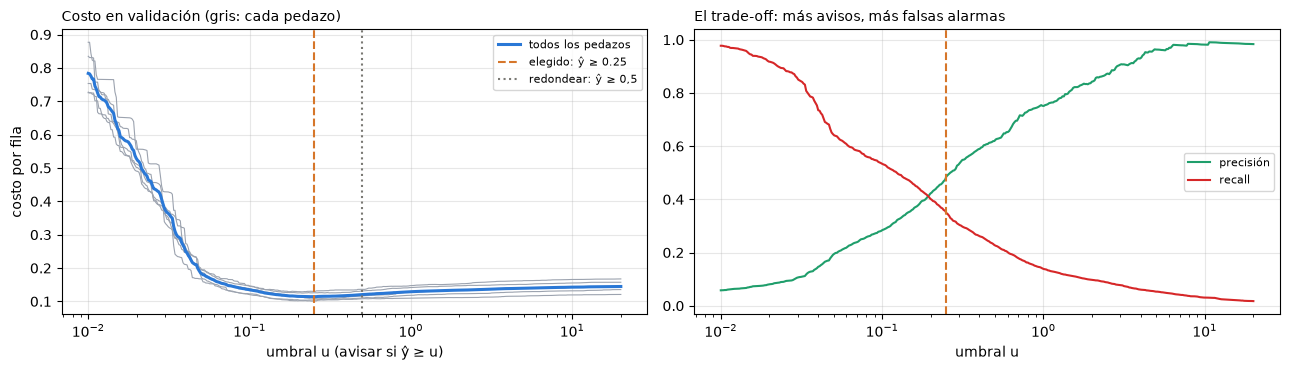

In [19]:
b = barrido(validacion)
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
for k, g in validacion.groupby("pedazo"):
    axes[0].plot(UMBRALES, barrido(g)["costo"], color="#9ca3af", lw=0.8)
axes[0].plot(UMBRALES, b["costo"], color="#2a78d6", lw=2.2, label="todos los pedazos")
axes[0].axvline(UMBRAL, color="#d6762a", ls="--", label=f"elegido: ŷ ≥ {UMBRAL:.2f}")
axes[0].axvline(0.5, color="#7a7974", ls=":", label="redondear: ŷ ≥ 0,5")
axes[0].set_xscale("log")
axes[0].set_xlabel("umbral u (avisar si ŷ ≥ u)")
axes[0].set_ylabel("costo por fila")
axes[0].set_title("Costo en validación (gris: cada pedazo)", fontsize=10, loc="left")
axes[0].legend(fontsize=8)
axes[1].plot(UMBRALES, b["precisión"], color="#1f9e6b", label="precisión")
axes[1].plot(UMBRALES, b["recall"], color="#d62728", label="recall")
axes[1].axvline(UMBRAL, color="#d6762a", ls="--")
axes[1].set_xscale("log")
axes[1].set_xlabel("umbral u")
axes[1].set_title("El trade-off: más avisos, más falsas alarmas", fontsize=10, loc="left")
axes[1].legend(fontsize=8)
for ax in axes:
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

- **Con "no avisar cuesta 3 falsas alarmas", el umbral es $\hat y \ge 0{,}25$.** Entre pedazos va de 0,21 a 0,33, o sea que es estable. Se avisa en el 3,5 % de las filas, con precisión 0,49 y recall 0,35: alrededor de una falsa alarma por acierto.
- **Redondear ($\hat y \ge 0{,}5$) era más conservador sin decirlo:** da precisión 0,62 y recall 0,23. Equivale a que no avisar cueste entre 1 y 2 falsas alarmas, lo contrario de lo que dijimos que preferíamos.
- **Si el grupo decide otra proporción, la tabla dice qué umbral corresponde.** Con 10×, se avisa en el 11 % de las filas y se detecta el 58 %, con 3 falsas alarmas por acierto. Con 1×, el umbral salta entre pedazos (0,46 a 2,28): no es estable.

# 11. El modelo final, medido una vez sobre el test

El modelo elegido, reentrenado con todo el entrenamiento, con el umbral elegido en validación. Intervalos de confianza por bootstrap **remuestreando sismos** (no filas).

In [20]:
modelo_final = busqueda.best_estimator_
pred_test = _pred(modelo_final, X_test)
act_test = _activas(X_test)
alerta_test = pred_test >= UMBRAL
pos_test = y_test.to_numpy() > 0


def fila_test(m):
    y, p = y_test.to_numpy()[m], pred_test[m]
    pos, al = y > 0, p >= UMBRAL
    return {"filas": int(m.sum()), "% con más réplicas": pos.mean() * 100, "PR-AUC piso": pos.mean(),
            "PR-AUC modelo": pr_auc(y, p), "precisión": precision_score(pos, al, zero_division=0),
            "recall": recall_score(pos, al), "F1": f1_score(pos, al),
            "MAE_log piso 0": mae_log(y, np.zeros_like(y)), "MAE_log modelo": mae_log(y, p),
            "MAE réplicas piso 0": y.mean(), "MAE réplicas modelo": mean_absolute_error(y, p)}


tabla_test = pd.DataFrame({"todas": fila_test(np.ones(len(y_test), bool)),
                           "activas (n_aft_t > 0)": fila_test(act_test),
                           "tranquilas (n_aft_t = 0)": fila_test(~act_test)}).T
display(tabla_test.round(3))

# bootstrap por sismo
rng = np.random.default_rng(SEMILLA)
grupos = test.groupby("cluster_id").indices
ids = np.array(list(grupos))
boot = []
for _ in range(1000):
    idx = np.concatenate([grupos[c] for c in rng.choice(ids, len(ids))])
    y, p, a = y_test.to_numpy()[idx], pred_test[idx], act_test[idx]
    boot.append({"PR-AUC · todas": pr_auc(y, p), "PR-AUC · activas": pr_auc(y[a], p[a]),
                 "precisión": precision_score(y > 0, p >= UMBRAL, zero_division=0),
                 "recall": recall_score(y > 0, p >= UMBRAL), "MAE_log · activas": mae_log(y[a], p[a])})
boot = pd.DataFrame(boot)
puntual = {"PR-AUC · todas": pr_auc(y_test, pred_test), "PR-AUC · activas": pr_auc(y_test[act_test], pred_test[act_test]),
           "precisión": precision_score(pos_test, alerta_test), "recall": recall_score(pos_test, alerta_test),
           "MAE_log · activas": mae_log(y_test[act_test], pred_test[act_test])}
pd.DataFrame({"test": puntual, "IC 95 % (2,5 %)": boot.quantile(0.025), "IC 95 % (97,5 %)": boot.quantile(0.975)}).round(3)

,filas,% con más réplicas,PR-AUC piso,PR-AUC modelo,precisión,recall,F1,MAE_log piso 0,MAE_log modelo,MAE réplicas piso 0,MAE réplicas modelo
todas,"21,225.000",4.702,0.047,0.431,0.462,0.398,0.427,0.050,0.068,0.155,0.153
activas (n_aft_t > 0),"1,578.000",25.729,0.257,0.734,0.523,0.783,0.627,0.339,0.288,1.406,1.075
tranquilas (n_aft_t = 0),"19,647.000",3.013,0.030,0.171,0.313,0.133,0.187,0.027,0.051,0.054,0.079


,test,"IC 95 % (2,5 %)","IC 95 % (97,5 %)"
PR-AUC · todas,0.431,0.369,0.485
PR-AUC · activas,0.734,0.657,0.792
precisión,0.462,0.410,0.512
recall,0.398,0.342,0.450
MAE_log · activas,0.288,0.259,0.320


- **Todas las filas:** PR-AUC **0,431** (IC 95 %: 0,369–0,485) contra 0,047 del piso, 9 veces el azar. En validación daba 0,394, dentro del intervalo. Con el umbral elegido: precisión 0,46, recall 0,40, F1 0,43.
- **Activas:** PR-AUC 0,734 contra 0,257 del piso, con recall 0,78 y precisión 0,52. El *cuántas* también le gana al piso: MAE_log 0,288 contra 0,339, y en réplicas 1,08 contra 1,41.
- **Tranquilas, lo difícil:** PR-AUC 0,171 contra 0,030 (5,7 veces el azar), pero el recall es sólo 0,13.
- **El MAE_log sobre todas las filas da peor que el piso** (0,068 contra 0,050). Con 95 % de ceros, decir siempre 0 es casi imbatible en esa métrica; por eso no es la métrica principal.

## La alerta: matriz de confusión y reporte por clase

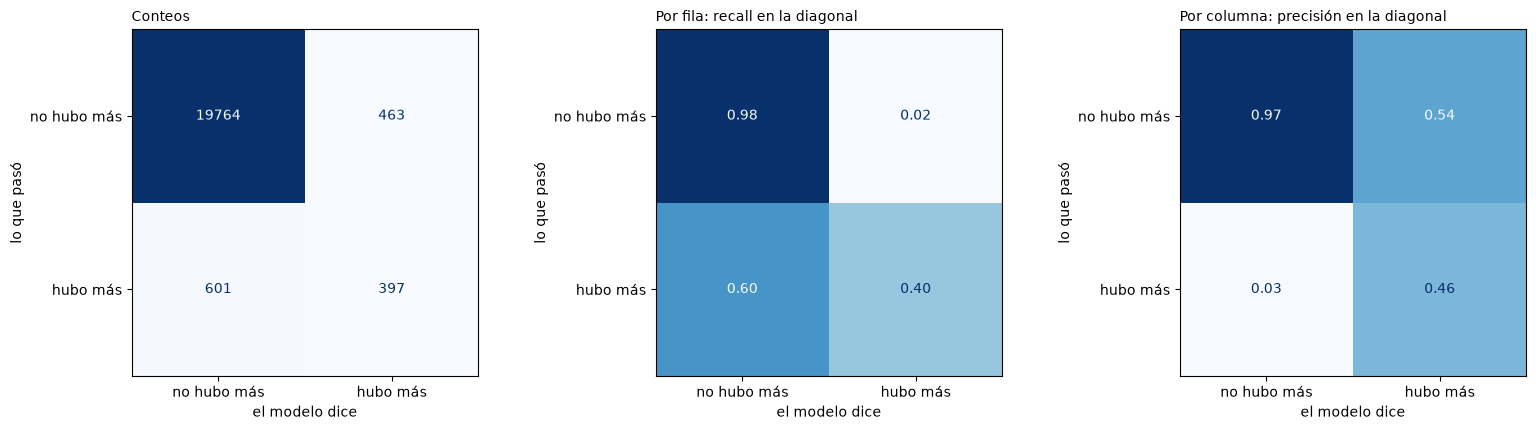

,precision,recall,f1-score,support
hubo más,0.462,0.398,0.427,998.000
no hubo más,0.970,0.977,0.974,"20,227.000"
accuracy,0.950,0.950,0.950,0.950
macro avg,0.716,0.687,0.701,"21,225.000"
weighted avg,0.947,0.950,0.948,"21,225.000"


In [21]:
from sklearn.metrics import ConfusionMatrixDisplay, classification_report

ETIQUETAS = ["no avisa / no hubo", "avisa / hubo"]
real_txt = np.where(pos_test, "hubo más", "no hubo más")
pred_txt = np.where(alerta_test, "hubo más", "no hubo más")
fig, axes = plt.subplots(1, 3, figsize=(16, 4.4))
for ax, norm, titulo, fmt in [(axes[0], None, "Conteos", "d"),
                              (axes[1], "true", "Por fila: recall en la diagonal", ".2f"),
                              (axes[2], "pred", "Por columna: precisión en la diagonal", ".2f")]:
    ConfusionMatrixDisplay.from_predictions(real_txt, pred_txt, labels=["no hubo más", "hubo más"], ax=ax,
                                            cmap="Blues", colorbar=False, normalize=norm, values_format=fmt)
    ax.set_title(titulo, fontsize=10, loc="left")
    ax.set_xlabel("el modelo dice")
    ax.set_ylabel("lo que pasó")
plt.tight_layout()
plt.show()
pd.DataFrame(classification_report(real_txt, pred_txt, output_dict=True)).T.round(3)

- **Por fila:** de los casos en que hubo más réplicas, el modelo avisó en el 40 % (recall); de los que no tuvieron, dejó tranquilo al 98 %.
- **Por columna:** cuando avisa acierta el 46 %; cuando no avisa, el 97 %.
- **La accuracy da 0,950:** decir siempre "no hubo más" daría 0,953. Es exactamente la trampa por la que no la usamos.

# 12. Un ejemplo: qué recibe el modelo y qué devuelve

Es lo que va a usar la app de la Entrega 4. **Recibe** una fila por consulta: el sismo principal (lo que se sabe en $t = 0$) y lo que se observó hasta la hora $t$. **Devuelve** cuántas réplicas más espera hasta los 30 días ($\hat y$) y si hay que avisar ($\hat y \ge$ `UMBRAL`).

Primero, un sismo inventado: un M6,2 en los Andes, consultado en tres momentos distintos.

In [22]:
def pronosticar(consultas):
    """Lo que usaría la app: cuántas réplicas más espera el modelo y si avisa."""
    y_hat = _pred(modelo_final, consultas[CANDIDATAS])
    return pd.DataFrame({"réplicas más esperadas (ŷ)": y_hat.round(2),
                         "alerta": np.where(y_hat >= UMBRAL, "AVISAR", "no avisar")}, index=consultas.index)


mc_region = df.groupby("region")["region_mc"].first()
principal = {"mainshock_mag": 6.2, "mainshock_depth": 25.0, "mainshock_lat": -31.5, "mainshock_lon": -71.8,
             "dist_to_border_km": 400.0, "region": "andes", "region_mc": mc_region["andes"],
             "n_prior_2d": 0, "n_prior_30d": 1, "n_prior_365d": 4, "prior_max_mag_365d": 4.8, "days_since_prior": 12.0}
consultas = pd.DataFrame([
    {**principal, "horizon_hours": 6, "n_aft_t": 4, "max_aft_mag_t": 5.1, "hours_since_last_t": 0.8},
    {**principal, "horizon_hours": 6, "n_aft_t": 0, "max_aft_mag_t": np.nan, "hours_since_last_t": 6.0},
    {**principal, "horizon_hours": 72, "n_aft_t": 9, "max_aft_mag_t": 5.1, "hours_since_last_t": 40.0},
], index=["a las 6 h, ya hubo 4 (la última hace 48 min)",
          "a las 6 h, todavía ninguna",
          "a las 72 h, hubo 9 (la última hace 40 h)"])

print("Lo que recibe:")
display(consultas[["mainshock_mag", "mainshock_depth", "region", "region_mc", "horizon_hours", "n_aft_t",
                   "max_aft_mag_t", "hours_since_last_t"]])
print(f"Lo que devuelve (avisa si ŷ ≥ {UMBRAL:.2f}):")
pronosticar(consultas)

Lo que recibe:


,mainshock_mag,mainshock_depth,region,region_mc,horizon_hours,n_aft_t,max_aft_mag_t,hours_since_last_t
"a las 6 h, ya hubo 4 (la última hace 48 min)",6.200,25.000,andes,4.500,6,4,5.100,0.800
"a las 6 h, todavía ninguna",6.200,25.000,andes,4.500,6,0,NaN,6.000
"a las 72 h, hubo 9 (la última hace 40 h)",6.200,25.000,andes,4.500,72,9,5.100,40.000


Lo que devuelve (avisa si ŷ ≥ 0.25):


,réplicas más esperadas (ŷ),alerta
"a las 6 h, ya hubo 4 (la última hace 48 min)",2.050,AVISAR
"a las 6 h, todavía ninguna",0.410,AVISAR
"a las 72 h, hubo 9 (la última hace 40 h)",0.860,AVISAR


- **A las 6 h, con 4 réplicas** (la última hace 48 min): espera 2 más y avisa.
- **A las 6 h, sin ninguna réplica:** espera 0,41. Es menos, pero un M6,2 sigue siendo un sismo grande y queda por encima del umbral (0,25), así que avisa igual.
- **A las 72 h, con 9 réplicas** y la última hace 40 h: espera menos de una (0,86). La secuencia se está apagando, pero todavía avisa.

Y un sismo real del test, seguido en sus cinco horizontes: el pronóstico se actualiza con lo que va pasando.

In [23]:
# el sismo de Michoacán del 19-sep-2022: ninguna réplica en la primera hora, pero vinieron después
caso = test[test["cluster_id"] == "us7000i9bw"]
print(f"{caso['mainshock_place'].iloc[0]} · {caso['mainshock_time'].iloc[0].date()} · M{caso['mainshock_mag'].iloc[0]}")
caso[["horizon_hours", "n_aft_t", "max_aft_mag_t", "hours_since_last_t"]].assign(
    **{"réplicas que realmente vinieron después": caso["y_aft"]}).join(pronosticar(caso)).set_index("horizon_hours").round(2)

35 km SSW of Aguililla, Mexico · 2022-09-19 · M7.6


,n_aft_t,max_aft_mag_t,hours_since_last_t,réplicas que realmente vinieron después,réplicas más esperadas (ŷ),alerta
horizon_hours,,,,,,
1,0,NaN,1.000,15,2.460,AVISAR
6,1,5.300,4.570,14,3.870,AVISAR
24,6,5.800,3.650,9,5.720,AVISAR
72,8,6.800,11.820,7,3.300,AVISAR
168,10,6.800,28.750,5,3.850,AVISAR


**Michoacán, M7,6, 19 de septiembre de 2022.**
- **En la primera hora no hubo ninguna réplica, pero después vinieron 15.** El modelo filtrado de la opción 1 no habría dicho nada; éste espera 2,5 y avisa.
- **Después se actualiza con lo que va pasando:**
  - a las 24 h, con 6 réplicas, espera 5,7 (vinieron 9);
  - a las 72 h ya hubo una réplica M6,8 y espera 3,3 (vinieron 7).
- **Avisa en los cinco momentos y acierta.** En la cantidad se queda corto, sobre todo al principio (2,5 contra 15 a la primera hora), que es el error típico en los sismos grandes (sección 13).

# 13. ¿Dónde se equivoca?

In [24]:
eval_test = test[["cluster_id", "mainshock_place", "mainshock_time", "region", "mainshock_mag", "horizon_hours",
                  "n_aft_t", "max_aft_mag_t", "hours_since_last_t"]].assign(
    real=y_test.to_numpy(), pred=pred_test, alerta=alerta_test, activa=act_test)


def por_grupo(g):
    pos = g["real"] > 0
    return pd.Series({"filas": len(g), "% con más réplicas": pos.mean() * 100,
                      "PR-AUC": average_precision_score(pos, g["pred"]) if pos.any() else np.nan,
                      "precisión": precision_score(pos, g["alerta"], zero_division=0),
                      "recall": recall_score(pos, g["alerta"], zero_division=0),
                      "MAE_log activas": mae_log(g.loc[g["activa"], "real"], g.loc[g["activa"], "pred"]) if g["activa"].any() else np.nan})


display(eval_test.groupby("horizon_hours").apply(por_grupo).round(3))
tramo = pd.cut(eval_test["mainshock_mag"], [0, 5, 6, 7, 10], labels=["< 5", "5–6", "6–7", "7 o más"], right=False)
eval_test.groupby(tramo, observed=True).apply(por_grupo).round(3)

,filas,% con más réplicas,PR-AUC,precisión,recall,MAE_log activas
horizon_hours,,,,,,
1,"4,245.000",7.892,0.388,0.430,0.364,0.529
6,"4,245.000",6.031,0.463,0.484,0.422,0.429
24,"4,245.000",4.641,0.445,0.487,0.381,0.295
72,"4,245.000",3.062,0.440,0.474,0.415,0.215
168,"4,245.000",1.885,0.446,0.447,0.475,0.143


,filas,% con más réplicas,PR-AUC,precisión,recall,MAE_log activas
mainshock_mag,,,,,,
< 5,"16,405.000",2.591,0.194,0.392,0.146,0.192
5–6,"4,390.000",8.793,0.406,0.419,0.409,0.348
6–7,380.000,36.842,0.809,0.471,0.929,0.497
7 o más,50.000,94.000,0.991,0.959,1.000,0.482


- **Por horizonte:** lo más difícil es la primera hora (PR-AUC 0,388), cuando todavía no se vio casi nada; de 6 h en adelante se estabiliza en 0,44–0,46. El error en la cantidad baja con el tiempo, de MAE_log 0,529 a 1 h a 0,143 a los 7 días, porque queda menos por pasar.
- **Por magnitud, funciona en sismos medianos y grandes:**
  - M6–7: PR-AUC 0,81 y recall 0,93.
  - M7 o más: 0,99 y recall 1,00.
  - M < 5 (el 77 % de las filas, sólo 2,6 % con más réplicas): PR-AUC 0,19 y recall 0,15. Un M4,7 casi nunca tiene réplicas, y cuando las tiene, nada de lo que se ve en las primeras horas lo anticipa.

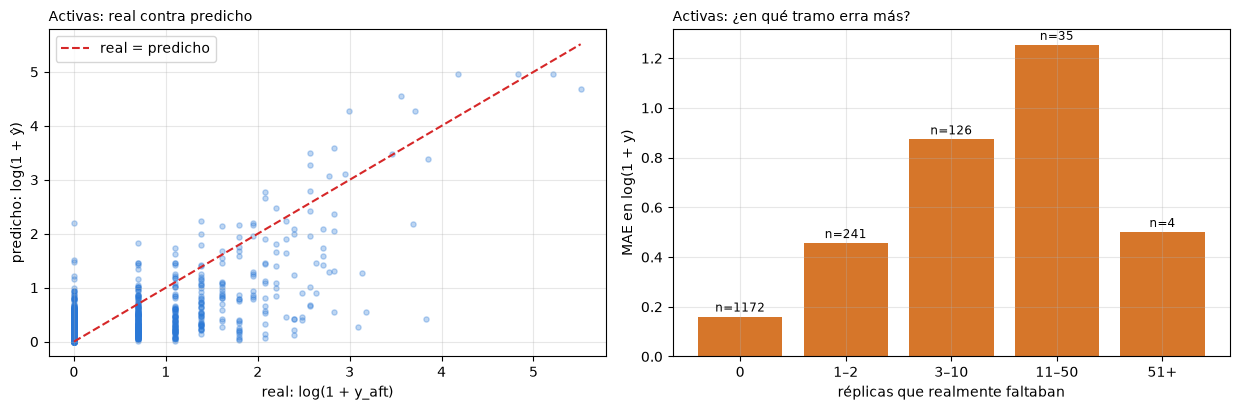

In [25]:
act = eval_test[eval_test["activa"]]
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.2))
axes[0].scatter(np.log1p(act["real"]), np.log1p(act["pred"]), s=14, alpha=0.3, color="#2a78d6")
lim = max(np.log1p(act["real"]).max(), np.log1p(act["pred"]).max())
axes[0].plot([0, lim], [0, lim], "--", color="#d62728", label="real = predicho")
axes[0].set_xlabel("real: log(1 + y_aft)")
axes[0].set_ylabel("predicho: log(1 + ŷ)")
axes[0].set_title("Activas: real contra predicho", fontsize=10, loc="left")
axes[0].legend()
tramo_y = pd.cut(act["real"], [-1, 0, 2, 10, 50, 10**6], labels=["0", "1–2", "3–10", "11–50", "51+"])
err = act.assign(err=np.abs(np.log1p(act["real"]) - np.log1p(act["pred"]))).groupby(tramo_y, observed=True)["err"].agg(["mean", "size"])
axes[1].bar(err.index.astype(str), err["mean"], color="#d6762a")
for i, (m, n) in enumerate(zip(err["mean"], err["size"])):
    axes[1].text(i, m + 0.02, f"n={n}", ha="center", fontsize=8.5)
axes[1].set_xlabel("réplicas que realmente faltaban")
axes[1].set_ylabel("MAE en log(1 + y)")
axes[1].set_title("Activas: ¿en qué tramo erra más?", fontsize=10, loc="left")
for ax in axes:
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [26]:
columnas = ["mainshock_place", "mainshock_time", "region", "mainshock_mag", "horizon_hours", "n_aft_t",
            "max_aft_mag_t", "real", "pred"]
no_aviso = eval_test[~eval_test["alerta"] & (eval_test["real"] > 0)].sort_values("real", ascending=False)
falsa = eval_test[eval_test["alerta"] & (eval_test["real"] == 0)].sort_values("pred", ascending=False)
print("No avisó y venían muchas (las 8 peores):")
display(no_aviso[columnas].head(8).assign(mainshock_time=lambda d: d["mainshock_time"].dt.date).round(2))
print("Avisó con más seguridad y no vino ninguna (las 8 peores):")
display(falsa[columnas].head(8).assign(mainshock_time=lambda d: d["mainshock_time"].dt.date).round(2))

No avisó y venían muchas (las 8 peores):


,mainshock_place,mainshock_time,region,mainshock_mag,horizon_hours,n_aft_t,max_aft_mag_t,real,pred
5505,"204 km SE of Port Blair, India",2022-07-04,sumatra_java,4.700,1,0,NaN,28.000,0.040
11421,"Izu Islands, Japan region",2023-10-03,japan,4.700,6,0,NaN,23.000,0.030
11422,"Izu Islands, Japan region",2023-10-03,japan,4.700,24,0,NaN,23.000,0.020
11420,"Izu Islands, Japan region",2023-10-03,japan,4.700,1,0,NaN,23.000,0.040
9715,"157 km SSE of Shimoda, Japan",2023-05-14,japan,4.700,1,0,NaN,14.000,0.040
6215,"182 km WSW of Pariaman, Indonesia",2022-08-28,sumatra_java,4.900,1,0,NaN,10.000,0.060
11294,"Izu Islands, Japan region",2023-09-21,japan,5.700,168,2,5.000,10.000,0.140
11293,"Izu Islands, Japan region",2023-09-21,japan,5.700,72,2,5.000,10.000,0.240


Avisó con más seguridad y no vino ninguna (las 8 peores):


,mainshock_place,mainshock_time,region,mainshock_mag,horizon_hours,n_aft_t,max_aft_mag_t,real,pred
11423,"Izu Islands, Japan region",2023-10-03,japan,4.700,72,23,6.100,0.000,8.070
1227,"121 km ENE of Hasaki, Japan",2021-08-03,japan,5.800,24,12,5.400,0.000,3.550
260,"53 km W of Labuan, Indonesia",2021-05-23,sumatra_java,5.100,1,3,5.200,0.000,3.370
7245,"Near the coast of Bio-Bio, Chile",2022-11-13,andes,5.700,1,2,6.200,0.000,2.350
3342,"80 km SW of Labuan, Indonesia",2022-01-14,sumatra_java,6.600,24,5,5.400,0.000,2.190
2531,"40 km S of Puerto San José, Guatemala",2021-11-18,mexico_ca,5.800,6,4,5.000,0.000,1.710
5754,"11 km NE of Bantay, Philippines",2022-07-27,philippines,7.000,168,11,5.200,0.000,1.570
16450,"239 km WNW of Cochrane, Chile",2024-11-08,andes,6.300,1,1,4.900,0.000,1.560


- **Los peores "no avisó" son enjambres:** Islas Izu (oct-2023, M4,7, 23 réplicas), Andamán al sureste de Port Blair (jul-2022, M4,7, 28) y Shimoda (may-2023, M4,7, 14).
  - El patrón es siempre el mismo: un sismo chico, ninguna réplica en la primera hora y después una ráfaga.
  - Son zonas de arco volcánico o de trasarco, donde la actividad no sigue el decaimiento de Omori a partir de un sismo principal.
  - Con `root`, además, el "principal" es el primer sismo chico del enjambre: el modelo ve un M4,7 y nada más.
- **Las peores falsas alarmas son el otro lado de lo mismo.**
  - La misma secuencia de Izu a las 72 h, con 23 réplicas y una M6,1, predice 8 más, y la secuencia se apagó.
  - Otras secuencias ya habían tenido una réplica mayor que el principal y no siguieron, como Bío-Bío en 2022 (principal M5,7, réplica M6,2 en la primera hora).

# 14. ¿En qué se apoya?

1. **Importancia por permutación** del modelo final sobre el test: desordenamos una columna de entrada por vez y medimos cuánto baja el PR-AUC.
2. **Coeficientes del modelo lineal** (`Ridge`, mismas columnas), con su signo.

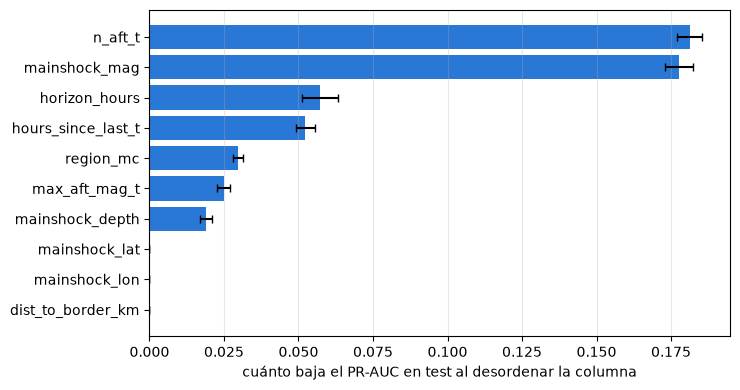

,baja del PR-AUC,desvío
n_aft_t,0.181,0.004
mainshock_mag,0.178,0.005
horizon_hours,0.057,0.006
hours_since_last_t,0.052,0.003
region_mc,0.030,0.002
max_aft_mag_t,0.025,0.002
mainshock_depth,0.019,0.002
mainshock_lat,0.000,0.000
mainshock_lon,0.000,0.000
dist_to_border_km,0.000,0.000


In [27]:
from sklearn.inspection import permutation_importance

perm = permutation_importance(modelo_final, X_test, y_test, scoring=score_pr_auc, n_repeats=10,
                              random_state=SEMILLA, n_jobs=-1)
importancia = pd.DataFrame({"baja del PR-AUC": perm.importances_mean, "desvío": perm.importances_std},
                           index=X_test.columns).sort_values("baja del PR-AUC", ascending=False)
fig, ax = plt.subplots(figsize=(7.5, 4))
top = importancia.head(10).iloc[::-1]
ax.barh(top.index, top["baja del PR-AUC"], xerr=top["desvío"], color="#2a78d6", capsize=3)
ax.set_xlabel("cuánto baja el PR-AUC en test al desordenar la columna")
ax.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()
importancia.round(4)

In [28]:
ridge = armar_pipeline(Ridge(alpha=10.0), **COLUMNAS_ELEGIDAS).fit(X_train, y_train)
nombres = ridge.named_steps["columnas"].transform(X_train.head()).columns
pd.DataFrame({"coeficiente (escalado)": ridge.named_steps["modelo"].regressor_.coef_}, index=nombres).sort_values(
    "coeficiente (escalado)", key=np.abs, ascending=False).round(3)

,coeficiente (escalado)
log_hours_since_last_t,-0.325
log_horizon_hours,0.306
mag_sobre_mc,0.131
log_n_aft_t,0.121
hubo_actividad,-0.106
tasa_por_hora_log,0.099
deficit_bath,-0.064
ratio_silencio,0.024
mainshock_depth,-0.012
max_aft_mag_t,-0.007


- **Lo que más pesa:** `n_aft_t` (el PR-AUC baja 0,181 al desordenarla) y `mainshock_mag` (0,178); después el horizonte (0,057) y las horas desde la última réplica (0,052). Es lo que un sismólogo miraría: cuánto ya se movió, qué tan grande fue, cuánto tiempo pasó y cuánto hace que no pasa nada.
- **¿Fuga?** `n_aft_t` cuenta sólo réplicas entre 0 y $t$, así que está disponible en $t$. La única advertencia viene del pipeline: la pertenencia a la secuencia usa un umbral η₀ ajustado con el catálogo completo. Es un parámetro global, no información del futuro de cada sismo.
- Posición, región y sismicidad previa dan 0 porque el bloque D no las usa.
- **Coeficientes de Ridge:**
  - Vienen menos réplicas cuanto más silencio (`log_hours_since_last_t`, −0,33).
  - Vienen más cuanto más grande es el sismo sobre Mc (+0,13), cuantas más réplicas ya hubo (+0,12) y cuanto mayor es la tasa (+0,10).
  - `log_horizon_hours` sale positivo (+0,31) sólo porque en los sismos tranquilos es igual a las horas de silencio: los dos coeficientes se compensan (−0,33 + 0,31).
  - El déficit de Båth sale negativo (−0,06): cuanto más chica es la mayor réplica frente al principal, menos vienen. Con `root`, un déficit negativo quiere decir que el principal era un premonitor, y entonces vienen más.

# 15. Resumen: lo que se probó y qué decidimos

| Qué se probó | Dónde | Qué dio | Qué decidimos |
|---|---|---|---|
| Predecir en $t = 0$, en 4 intervalos, con Poisson + empuje | `Entrega_3` | Le ganó a la logística y al random forest; F1 macro 0,50 en test (piso 0,24), con unas 800 falsas alarmas | Queda como referencia. Acá es el bloque A (sólo lo que se sabe en $t = 0$): PR-AUC 0,327, contra 0,395 al mirar las primeras horas |
| Región y sismos de los 30 días previos | `Entrega_3` | No mejoraron por más que el desvío | Afuera; acá tampoco mejoran (bloques E y F) |
| `mainshock=largest`, sin tope de distancia | opción 1 | Métricas más altas (F1 0,67 en activas) | Descartado: elige el principal mirando el futuro (acá, el 31 % de las activas tiene una réplica mayor que el principal) y encadena sismos a 3.700 km. Usamos `root` + `gk3` |
| Entrenar sólo con sismos activos | opción 1 | En activas empata (0,684 contra 0,685); en todas pierde (0,273 contra 0,395) | Sin filtro |
| Validar por sismo sin respetar la fecha (`GroupKFold`) | opción 1 | Optimista: 0,412 contra 0,395 | Por fecha y por sismo, con purga de 30 días |
| Redondear para avisar ($\hat y \ge 0{,}5$) | opción 1 | Precisión 0,62, recall 0,23 | Umbral por costo: $\hat y \ge 0{,}25$ |
| MAE_log como métrica principal | opción 1 | Sobre todas las filas, decir siempre 0 le gana al modelo | PR-AUC como principal; MAE_log sólo para el *cuántas* en las activas |
| Comparar A y B por su precisión | `Comparativa_Entrega_3` | Comparaba poblaciones distintas (10,7 % contra 26,9 % de positivos) | Comparación sobre las mismas filas (bloque A contra C, sección 6) |

**Límite que queda:** los enjambres, sismos chicos que después tienen una ráfaga de réplicas. Nada de lo que se ve en las primeras horas los anticipa.

**Para la Entrega 4:** el modelo es `modelo_final` con el umbral `UMBRAL` (ejemplo en la sección 12). Pendientes:
- mostrar una probabilidad calibrada en vez de un conteo;
- revisar un umbral por horizonte.